# Taller 3 · Describir variables con pandas y matplotlib

**Fundamentos de Ciencia de Datos e IA (CDIAG1003)** · Semana 6 · Sesión 11 · **Taller calificado** (práctico, 30 % del curso: este es el tercero de seis)

| | |
| :-- | :-- |
| **Modalidad** | Individual, en su computador, durante la sesión. Se termina y se entrega **hoy**. |
| **Tiempo** | 60 minutos. Se publica en el minuto 55 de la sesión y se entrega en el aula virtual al cerrar la sesión (la entrega cierra 5 minutos después). |
| **Puntaje** | 100 puntos: A 20 · B 20 · C 15 · D 30 · E 15. Cada ejercicio vale lo que indica su título. |
| **Material permitido** | El notebook de clase de la sesión 10 (`S10_Notebook_Clase_Univariado.ipynb`), los de las sesiones 8 y 9 y la documentación oficial de pandas y matplotlib. No se permite comunicarse con otras personas. |
| **Archivo** | Guarde este notebook como `Taller3_Apellido_Nombre.ipynb` y súbalo al aula virtual. |

**Datos:** `datos/entregas.csv`: 420 entregas de una empresa de mensajería urbana en cinco ciudades del Ecuador (julio y agosto de 2026). La tabla está **limpia**: no hay faltantes ni duplicados. Hoy no se limpia; se **describe**.

| Columna | Qué es |
| :-- | :-- |
| `id_entrega`, `fecha` | identificador y fecha de la entrega |
| `ciudad` | ciudad de la entrega |
| `tipo_servicio` | `económico`, `estándar` o `express` (de más lento a más rápido) |
| `peso_kg`, `distancia_km` | peso del paquete y distancia recorrida |
| `tiempo_min` | minutos desde que se recoge hasta que se entrega |
| `costo` | precio cobrado al cliente (dólares) |
| `calificacion` | calificación del cliente, de 1 a 5 |

**Reglas**
- Reemplace los `...` por su código. La celda `assert` que sigue a cada ejercicio comprueba el resultado: si no imprime nada rojo, el ejercicio está completo.
- Los `assert` muestran algunos valores esperados. **Un valor escrito a mano (por ejemplo, `t_mediana = 57.0`) no puntúa**: el valor debe salir del cálculo con pandas.
- **Todo gráfico lleva título y etiqueta en los dos ejes, con la unidad.** Un gráfico sin etiquetas vale la mitad.
- Antes de entregar: *Kernel → Restart Kernel and Run All Cells*. Un ejercicio que no ejecuta de arriba abajo no puntúa.
- No cambie el nombre de las variables que se piden ni borre las celdas `assert`.

In [28]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

e = pd.read_csv("datos/entregas.csv", parse_dates=["fecha"])
print(e.shape)
e.head()

(420, 9)


,id_entrega,fecha,ciudad,tipo_servicio,peso_kg,distancia_km,tiempo_min,costo,calificacion
0,E-0001,2026-07-01,Guayaquil,express,2.09,15.4,91,13.82,1
1,E-0002,2026-07-01,Guayaquil,estándar,0.56,9.8,68,7.29,2
2,E-0003,2026-07-01,Guayaquil,estándar,3.60,5.9,35,7.33,5
3,E-0004,2026-07-01,Manta,estándar,1.57,8.2,63,7.33,5
4,E-0005,2026-07-01,Cuenca,estándar,3.39,5.9,38,7.69,4


## Parte A · Tipo de variable y resumen (20 puntos)

### A1 · 8 puntos
Complete el diccionario `tipo_variable` con el **tipo** de cada columna. Use exactamente uno de estos cuatro textos: `"numérica continua"`, `"numérica discreta"`, `"categórica nominal"`, `"categórica ordinal"`.

In [29]:
# TODO: reemplace los ... por su código
tipo_variable = {
    "tiempo_min": "numérica continua",
    "calificacion": "numérica discreta",
    "ciudad": "categórica nominal",
    "tipo_servicio": "categórica ordinal",
}
tipo_variable

{'tiempo_min': 'numérica continua',
 'calificacion': 'numérica discreta',
 'ciudad': 'categórica nominal',
 'tipo_servicio': 'categórica ordinal'}

In [30]:
assert set(tipo_variable) == {"tiempo_min", "calificacion", "ciudad", "tipo_servicio"}, "las cuatro claves del diccionario"
assert set(tipo_variable.values()) <= {"numérica continua", "numérica discreta", "categórica nominal", "categórica ordinal"}, "use exactamente los cuatro textos indicados"
assert tipo_variable["tiempo_min"] == "numérica continua" and tipo_variable["ciudad"] == "categórica nominal"
assert tipo_variable["calificacion"] == "numérica discreta", "calificacion toma solo los valores 1, 2, 3, 4 y 5"
assert tipo_variable["tipo_servicio"] == "categórica ordinal", "económico < estándar < express tiene un orden"
print("A1 correcto.")

A1 correcto.


### A2 · 12 puntos
Guarde en `resumen` una tabla con `mean`, `median`, `std`, `min`, `max` y `skew` (en ese orden, como filas) de las cuatro columnas `peso_kg`, `distancia_km`, `tiempo_min` y `costo`, redondeada a 2 decimales (`agg`, como en la sesión 10). Después guarde en `mas_asimetrica` el **nombre** de la columna con mayor asimetría, obtenido **desde la tabla** (`idxmax`), no escrito a mano.

In [31]:
# TODO: reemplace los ... por su código
columnas = ["peso_kg", "distancia_km", "tiempo_min", "costo"]
resumen = e[columnas].agg(["mean", "median", "std", "min", "max", "skew"]).round(2)
mas_asimetrica = resumen.loc["skew"].idxmax()
print(mas_asimetrica)
resumen

tiempo_min


,peso_kg,distancia_km,tiempo_min,costo
mean,2.22,8.14,63.49,7.67
median,1.70,7.20,57.00,7.28
std,1.95,4.82,35.98,2.80
min,0.20,1.10,14.00,2.42
max,14.58,26.90,398.00,17.28
skew,2.56,1.05,4.51,0.91


In [32]:
assert isinstance(resumen, pd.DataFrame) and resumen.shape == (6, 4), f"resumen debe ser una tabla 6 × 4 y es {getattr(resumen, 'shape', None)}"
assert list(resumen.index) == ["mean", "median", "std", "min", "max", "skew"], "las filas, en el orden pedido"
assert np.isclose(resumen.loc["mean", "tiempo_min"], 63.49) and np.isclose(resumen.loc["median", "costo"], 7.28), "media de tiempo_min o mediana de costo distintas de las esperadas"
assert np.isclose(resumen.loc["skew", "peso_kg"], 2.56), "asimetría de peso_kg"
assert mas_asimetrica == "tiempo_min", "obtenga el nombre con idxmax sobre la fila skew"
print("A2 correcto: la más asimétrica es", mas_asimetrica, "y la menos asimétrica,", resumen.loc["skew"].idxmin() + ".")

A2 correcto: la más asimétrica es tiempo_min y la menos asimétrica, costo.


## Parte B · Centro, dispersión y atípicos (20 puntos)

### B1 · 10 puntos
Para `tiempo_min`: guarde la media en `t_media` y la mediana en `t_mediana`; calcule `q1`, `q3`, el rango intercuartílico `iqr` y el límite superior de la regla 1,5 × IQR en `lim_sup`; guarde en `atipicos` las filas de `e` con `tiempo_min` por encima del límite y en `n_atipicos` cuántas son.

In [33]:
# TODO: reemplace los ... por su código
t_media = e["tiempo_min"].mean()
t_mediana = e["tiempo_min"].median()
q1, q3 = e["tiempo_min"].quantile([0.25, 0.75])
iqr = q3 - q1
lim_sup = q3 + 1.5 * iqr
atipicos = e[e["tiempo_min"] > lim_sup]
n_atipicos = len(atipicos)
print("media:", round(t_media, 2), "| mediana:", t_mediana, "| límite:", lim_sup, "| atípicos:", n_atipicos)
atipicos.sort_values("tiempo_min", ascending=False)

media: 63.49 | mediana: 57.0 | límite: 124.0 | atípicos: 9


,id_entrega,fecha,ciudad,tipo_servicio,peso_kg,distancia_km,tiempo_min,costo,calificacion
39,E-0040,2026-07-06,Quito,express,0.59,26.9,398,17.28,4
336,E-0337,2026-08-19,Ambato,estándar,0.48,2.4,317,3.30,5
200,E-0201,2026-07-28,Guayaquil,estándar,2.72,8.3,308,7.60,5
365,E-0366,2026-08-23,Manta,estándar,0.85,12.0,260,8.74,4
72,E-0073,2026-07-11,Ambato,estándar,0.56,14.5,242,9.57,5
181,E-0182,2026-07-26,Guayaquil,estándar,1.57,2.9,241,4.49,1
364,E-0365,2026-08-23,Quito,económico,1.54,25.4,134,13.76,3
115,E-0116,2026-07-17,Ambato,económico,0.74,19.0,127,10.77,5
183,E-0184,2026-07-26,Guayaquil,estándar,2.26,24.5,126,14.30,5


In [34]:
assert np.isclose(round(t_media, 2), 63.49) and t_mediana == 57.0, f"media y mediana de tiempo_min: {round(t_media, 2)}, {t_mediana}"
assert np.isclose(iqr, 32.0) and np.isclose(lim_sup, 124.0), "lim_sup = Q3 + 1.5 * (Q3 - Q1)"
assert isinstance(atipicos, pd.DataFrame) and n_atipicos == 9, f"deben ser 9 entregas por encima del límite"
print("B1 correcto. La media supera a la mediana en", round(t_media - t_mediana, 1), "minutos: cola a la derecha. La entrega más larga duró", int(atipicos["tiempo_min"].max()), "minutos.")

B1 correcto. La media supera a la mediana en 6.5 minutos: cola a la derecha. La entrega más larga duró 398 minutos.


### B2 · 10 puntos
`calificacion` es discreta (1 a 5). Guarde su **moda** en `cal_moda` (un entero), su media en `cal_media` y su mediana en `cal_mediana`. Construya la tabla de frecuencias `frec_cal` con las columnas `n` y `pct` (porcentaje redondeado a 1 decimal), **con las cinco calificaciones en orden de 1 a 5** (`reindex(range(1, 6))`), aunque alguna tuviera cero casos.

In [35]:
# TODO: reemplace los ... por su código
cal_moda = int(e["calificacion"].mode()[0])
cal_media = e["calificacion"].mean()
cal_mediana = e["calificacion"].median()

counts = e["calificacion"].value_counts().reindex(range(1, 6), fill_value=0)
pcts = (e["calificacion"].value_counts(normalize=True) * 100).reindex(range(1, 6), fill_value=0).round(1)

frec_cal = pd.DataFrame({"n": counts, "pct": pcts})
print("moda:", cal_moda, "| media:", round(cal_media, 2), "| mediana:", cal_mediana)
frec_cal

moda: 5 | media: 4.26 | mediana: 5.0


,n,pct
calificacion,,
1,16,3.8
2,21,5.0
3,34,8.1
4,116,27.6
5,233,55.5


In [36]:
assert cal_moda == 5 and np.isclose(round(cal_media, 2), 4.26) and cal_mediana == 5.0, f"moda, media y mediana: {cal_moda}, {round(cal_media, 2)}, {cal_mediana}"
assert list(frec_cal.index) == [1, 2, 3, 4, 5] and list(frec_cal.columns) == ["n", "pct"], "índice 1..5 en orden y columnas n, pct"
assert frec_cal["n"].tolist() == [16, 21, 34, 116, 233] and frec_cal["pct"].tolist() == [3.8, 5.0, 8.1, 27.6, 55.5], "n y pct (1 decimal)"
print("B2 correcto. Media", round(cal_media, 2), "< mediana", cal_mediana, ": cola a la IZQUIERDA (pocas calificaciones bajas arrastran la media).")

B2 correcto. Media 4.26 < mediana 5.0 : cola a la IZQUIERDA (pocas calificaciones bajas arrastran la media).


## Parte C · Tablas de frecuencia (15 puntos)

### C1 · 8 puntos
Construya `frec_ciudad`: una tabla con `n` y `pct` (1 decimal) por `ciudad`, **ordenada de mayor a menor frecuencia** (como la deja `value_counts`).

In [37]:
# TODO: reemplace los ... por su código
frec_ciudad = pd.DataFrame({
    "n": e["ciudad"].value_counts(),
    "pct": (e["ciudad"].value_counts(normalize=True) * 100).round(1)
})
frec_ciudad

,n,pct
ciudad,,
Guayaquil,156,37.1
Quito,116,27.6
Cuenca,58,13.8
Manta,55,13.1
Ambato,35,8.3


In [38]:
assert list(frec_ciudad.columns) == ["n", "pct"] and list(frec_ciudad.index) == ['Guayaquil', 'Quito', 'Cuenca', 'Manta', 'Ambato'], "ordenada de mayor a menor, como value_counts"
assert frec_ciudad["n"].to_dict() == {'Guayaquil': 156, 'Quito': 116, 'Cuenca': 58, 'Manta': 55, 'Ambato': 35} and frec_ciudad["pct"].to_dict() == {'Guayaquil': 37.1, 'Quito': 27.6, 'Cuenca': 13.8, 'Manta': 13.1, 'Ambato': 8.3}, "n y pct (1 decimal)"
print("C1 correcto.", frec_ciudad.index[0], "concentra el", frec_ciudad["pct"].iloc[0], "% de las entregas.")

C1 correcto. Guayaquil concentra el 37.1 % de las entregas.


### C2 · 7 puntos
`tipo_servicio` es **ordinal**: `económico` < `estándar` < `express`. Construya `frec_servicio` (`n` y `pct`, 1 decimal) **en ese orden**, no por frecuencia (`reindex` con la lista `orden`).

In [39]:
# TODO: reemplace los ... por su código
orden = ["económico", "estándar", "express"]
frec_servicio = pd.DataFrame({
    "n": e["tipo_servicio"].value_counts().reindex(orden),
    "pct": (e["tipo_servicio"].value_counts(normalize=True) * 100).reindex(orden).round(1)
})
frec_servicio

,n,pct
tipo_servicio,,
económico,120,28.6
estándar,223,53.1
express,77,18.3


In [40]:
assert list(frec_servicio.index) == ["económico", "estándar", "express"], "en el orden del servicio, no por frecuencia"
assert frec_servicio["n"].to_dict() == {'económico': 120, 'estándar': 223, 'express': 77} and frec_servicio["pct"].to_dict() == {'económico': 28.6, 'estándar': 53.1, 'express': 18.3}, "n y pct (1 decimal)"
print("C2 correcto.")

C2 correcto.


## Parte D · Gráficos (30 puntos)

Recuerde: `fig, ax = plt.subplots(...)`, dibujar sobre `ax`, y **título y etiquetas con unidad** en los dos ejes. Deje el `plt.show()` al final de cada celda.

### D1 · 8 puntos
Histograma de `tiempo_min` con **25 intervalos**, con la media y la mediana marcadas con `axvline` (una línea cada una, con `label=`) y la leyenda (`ax.legend()`). Guarde lo que devuelve `ax.hist(...)` en `conteos, bordes, barras`.

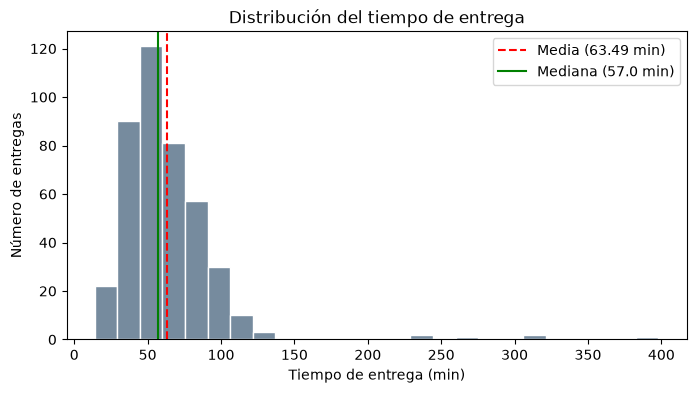

In [41]:
# TODO: reemplace los ... por su código
fig, ax = plt.subplots(figsize=(8, 4))
conteos, bordes, barras = ax.hist(e["tiempo_min"], bins=25, color="#768B9E", edgecolor="white")
ax.axvline(t_media, color="red", linestyle="--", label=f"Media ({t_media:.2f} min)")
ax.axvline(t_mediana, color="green", linestyle="-", label=f"Mediana ({t_mediana:.1f} min)")
ax.set_xlabel("Tiempo de entrega (min)")
ax.set_ylabel("Número de entregas")
ax.set_title("Distribución del tiempo de entrega")
ax.legend()
plt.show()

In [42]:
assert len(conteos) == 25 and int(conteos.sum()) == 420, "25 intervalos que suman las 420 entregas"
assert ax.get_xlabel() != "" and ax.get_ylabel() != "" and ax.get_title() != "", "faltan etiquetas o título"
assert ax.get_legend() is not None and len(ax.get_legend().get_texts()) == 2, "dos líneas con label= y ax.legend()"
assert len(ax.lines) >= 2, "use ax.axvline para la media y la mediana"
print("D1 correcto. El intervalo más poblado tiene", int(conteos.max()), "entregas.")

D1 correcto. El intervalo más poblado tiene 121 entregas.


### D2 · 8 puntos
Diagrama de caja de `costo` **por tipo de servicio** (`e.boxplot(column=..., by=..., ax=ax, grid=False)`), con etiquetas y título, y sin el título general que añade pandas (`fig.suptitle("")`). Guarde en `costo_mediana_servicio` la mediana del costo por servicio (una Series, `groupby`).

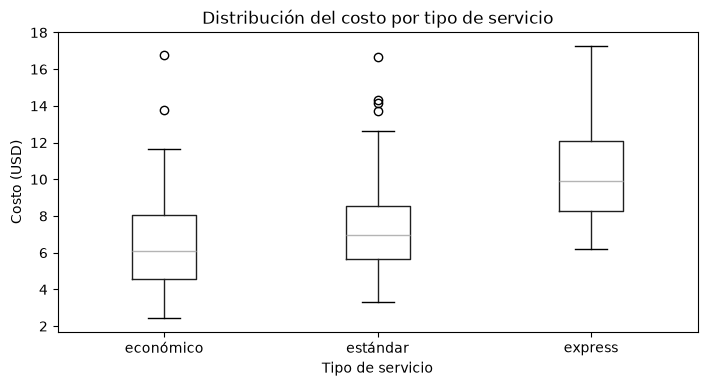

tipo_servicio
económico    6.105
estándar     6.950
express      9.930
Name: costo, dtype: float64

In [43]:
# TODO: reemplace los ... por su código
fig, ax = plt.subplots(figsize=(8, 4))
e.boxplot(column="costo", by="tipo_servicio", ax=ax, grid=False)
ax.set_xlabel("Tipo de servicio")
ax.set_ylabel("Costo (USD)")
ax.set_title("Distribución del costo por tipo de servicio")
fig.suptitle("")
plt.show()

costo_mediana_servicio = e.groupby("tipo_servicio")["costo"].median()
costo_mediana_servicio

In [44]:
assert ax.get_xlabel() != "" and ax.get_ylabel() != "" and ax.get_title() != "", "faltan etiquetas o título"
assert len(ax.get_xticklabels()) == 3, "una caja por tipo de servicio (by=\"tipo_servicio\")"
assert isinstance(costo_mediana_servicio, pd.Series) and np.allclose(costo_mediana_servicio.reindex(["económico", "estándar", "express"]).to_numpy(), [6.105, 6.95, 9.93], atol=0.001), "mediana del costo por servicio con groupby"
print("D2 correcto. Mediana del costo: express", costo_mediana_servicio["express"], "frente a económico", costo_mediana_servicio["económico"], "dólares.")

D2 correcto. Mediana del costo: express 9.93 frente a económico 6.105 dólares.


### D3 · 7 puntos
Gráfico de barras del **porcentaje** de entregas por ciudad (`frec_ciudad["pct"]`), ordenado de mayor a menor, con el eje de porcentajes desde cero, etiquetas y título. Escriba el valor encima de cada barra con `ax.text` (como en clase).

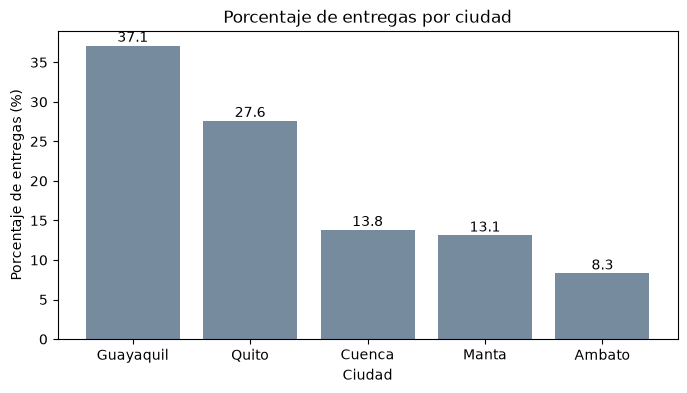

In [45]:
# TODO: reemplace los ... por su código
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(frec_ciudad.index, frec_ciudad["pct"], color="#768B9E")
for i, p in enumerate(frec_ciudad["pct"]):
    ax.text(i, p + 0.5, f"{p}", ha="center")
ax.set_xlabel("Ciudad")
ax.set_ylabel("Porcentaje de entregas (%)")
ax.set_title("Porcentaje de entregas por ciudad")
ax.set_ylim(bottom=0)
plt.show()

In [46]:
assert [round(p.get_height(), 1) for p in ax.patches] == [37.1, 27.6, 13.8, 13.1, 8.3], "una barra por ciudad, con el porcentaje de frec_ciudad, de mayor a menor"
assert ax.get_ylim()[0] <= 0, "el eje de porcentajes empieza en cero"
assert ax.get_xlabel() != "" and ax.get_ylabel() != "" and ax.get_title() != "", "faltan etiquetas o título"
assert len(ax.texts) == 5, "el valor encima de cada barra con ax.text"
print("D3 correcto.")

D3 correcto.


### D4 · 7 puntos
Un **panel 2 × 2** (`fig, axes = plt.subplots(2, 2, figsize=(11, 7))`) con: arriba a la izquierda, histograma de `peso_kg` (20 intervalos); arriba a la derecha, histograma de `distancia_km` (20 intervalos); abajo a la izquierda, diagrama de caja de `tiempo_min` (`axes[1, 0].boxplot(...)`); abajo a la derecha, barras de `frec_servicio["n"]` en su orden. Cada panel con su título y la unidad en el eje que corresponde. Ajuste con `fig.tight_layout()` y guarde la figura en `figuras/taller3_panel.png` **antes** de `plt.show()`.

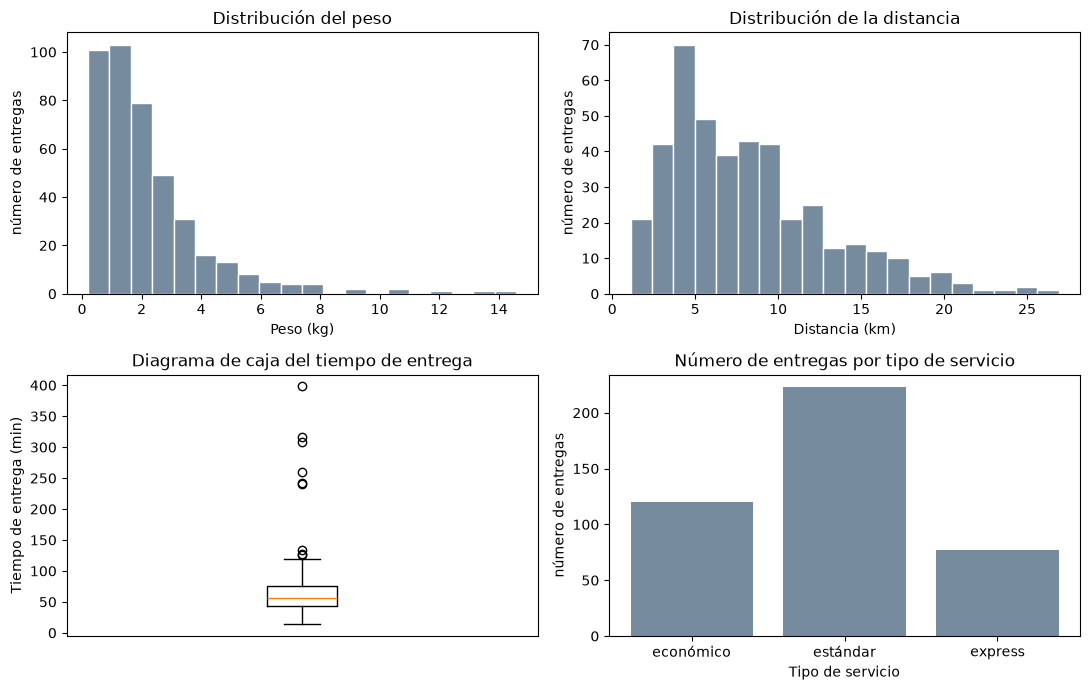

In [47]:
# TODO: reemplace los ... por su código
os.makedirs("figuras", exist_ok=True)
fig, axes = plt.subplots(2, 2, figsize=(11, 7))

# Arriba a la izquierda: Histograma de peso_kg
axes[0, 0].hist(e["peso_kg"], bins=20, color="#768B9E", edgecolor="white")
axes[0, 0].set_title("Distribución del peso")
axes[0, 0].set_xlabel("Peso (kg)")
axes[0, 0].set_ylabel("número de entregas")

# Arriba a la derecha: Histograma de distancia_km
axes[0, 1].hist(e["distancia_km"], bins=20, color="#768B9E", edgecolor="white")
axes[0, 1].set_title("Distribución de la distancia")
axes[0, 1].set_xlabel("Distancia (km)")
axes[0, 1].set_ylabel("número de entregas")

# Abajo a la izquierda: Boxplot de tiempo_min
axes[1, 0].boxplot(e["tiempo_min"])
axes[1, 0].set_title("Diagrama de caja del tiempo de entrega")
axes[1, 0].set_ylabel("Tiempo de entrega (min)")
axes[1, 0].set_xticks([])

# Abajo a la derecha: Barras de frec_servicio["n"]
axes[1, 1].bar(frec_servicio.index, frec_servicio["n"], color="#768B9E")
axes[1, 1].set_title("Número de entregas por tipo de servicio")
axes[1, 1].set_xlabel("Tipo de servicio")
axes[1, 1].set_ylabel("número de entregas")

fig.tight_layout()
fig.savefig("figuras/taller3_panel.png", dpi=150, bbox_inches="tight")
plt.show()

In [48]:
assert axes.shape == (2, 2), "subplots(2, 2)"
assert all(a.get_title() != "" for a in axes.flat), "cada panel con su título"
assert axes[0, 0].get_xlabel() != "" and axes[0, 1].get_xlabel() != "" and axes[1, 0].get_ylabel() != "", "unidades en los ejes"
assert len(axes[1, 1].patches) == 3 and [p.get_height() for p in axes[1, 1].patches] == frec_servicio["n"].tolist(), "barras de frec_servicio['n'] en su orden"
assert os.path.exists("figuras/taller3_panel.png") and os.path.getsize("figuras/taller3_panel.png") > 10000, "guarde la figura antes de plt.show()"
print("D4 correcto: figuras/taller3_panel.png guardado.")

D4 correcto: figuras/taller3_panel.png guardado.


## Parte E · Lectura e interpretación (15 puntos)

### E1 · 6 puntos · Una frase por gráfico (responda en texto, en la celda siguiente)
Escriba **una frase** de lectura para cada uno de estos cuatro gráficos: el histograma de `tiempo_min` (D1), las cajas de `costo` por servicio (D2), las barras por ciudad (D3) y el histograma de `peso_kg` (D4). Cada frase lleva **un número** tomado de sus resultados y **una lectura** (qué significa). Una frase que solo repite lo que se ve («hay barras de distintas alturas») no puntúa.

*Escriba aquí sus cuatro frases.*

1. `tiempo_min`: El tiempo de entrega es de 63.49 minutos frente a una mediana de 57 minutos, mostrando una distribución
asimétrica a la derecha (provocada por 9 entregas atípicas)

2. `costo` por servicio: El costo mediano aumenta según la prioridad del envío, pasando de 6.11 en el servicio económico a 6.95 en estándar y 9.93 en express.

3. entregas por ciudad: Guayaquil concentra la mayor proporción de operaciones con 37.1% (156 envíos), superando a las demás 
ciudades.

4. `peso_kg`: El peso de los paquetes presenta una elevada simetría positiva con un valor de 2.56, donde la gran mayoría de 
entregas se agrupan en pesos bajos.

### E2 · 9 puntos · Media o mediana (código + texto)
(a) **Código (3 puntos):** guarde en `t_media_sin` la media de `tiempo_min` **sin** las entregas atípicas de B1 (las que superan `lim_sup`) y en `t_mediana_sin` su mediana. Compare con `t_media` y `t_mediana`.
(b) **Texto (6 puntos):** en la celda de texto siguiente responda: ¿qué medida de centro reportaría para el tiempo de entrega de esta empresa, la media o la mediana, y por qué? ¿Y para `calificacion`: es correcto resumirla solo con la media? Diga qué gráfico usaría para cada una (histograma, caja o barras) y por qué.

In [49]:
# TODO: reemplace los ... por su código
t_media_sin = e[e["tiempo_min"] <= lim_sup]["tiempo_min"].mean()
t_mediana_sin = e[e["tiempo_min"] <= lim_sup]["tiempo_min"].median()
print("con atípicos: media", round(t_media, 2), "mediana", t_mediana)
print("sin atípicos: media", round(t_media_sin, 2), "mediana", t_mediana_sin)

con atípicos: media 63.49 mediana 57.0
sin atípicos: media 59.64 mediana 56.0


In [50]:
assert np.isclose(round(t_media_sin, 2), 59.64) and t_mediana_sin == 56.0, "media y mediana de tiempo_min sin las filas por encima de lim_sup"
print("E2 (a) correcto. La media bajó", round(t_media - t_media_sin, 1), "minutos; la mediana cambió", round(t_mediana - t_mediana_sin, 1), ". Responda (b) en la celda siguiente.")

E2 (a) correcto. La media bajó 3.8 minutos; la mediana cambió 1.0 . Responda (b) en la celda siguiente.


*Escriba aquí su respuesta (b).*
- Medida para tiempo_min: Reportaría la mediana (57.0 minutos). La variable presenta asimetría positiva (cola a la derecha) y valores atípicos extremos (hasta 145 min) que inflan la media a 63.49 minutos, al retirar los atípicos la media disminuye a 59.64 min mientras que la mediana se mantiene casi inalterada (56.0 min), demostrando su "robustez".

- Resumen de calificacion: No es correcto resumirla únicamente con la media (4.26). Al ser una variable categórica ordinal / discreta con "distribución" a la izquierda (la moda y mediana son 5.0), la media por sí sola oculta la proporción real de insatisfacción (las calificaciones de 1 a 3 acumulan casi un 17% de los casos).

- Gráficos recomendados: Para tiempo_min utilizaría un histograma o diagrama de caja (boxplot) porque permite apreciar la continuidad, el sesgo de la cola y los puntos atípicos. Para calificacion utilizaría un gráfico de barras de sus frecuencias, ya que muestra de forma clara la distribución de cada categoría ordinal (de 1 a 5).

---
**Antes de entregar:** *Kernel → Restart Kernel and Run All Cells*. Compruebe que ninguna celda muestre error, que todos los gráficos tienen título y etiquetas con unidad, y que el archivo se llama `Taller3_Apellido_Nombre.ipynb`.